# 03c — Human-vs-fusion specialist encoder

Almost all remaining errors are **human ↔ fusion** (ai is ~0.995 F1). This fine-tunes the same mDeBERTa-v3 (head+tail inputs) as a **binary** classifier on **all human and fusion rows outside the fixed val split** (~135k, 1 epoch), so its whole capacity goes to that boundary. Its logits for every val/test text (including ai texts) are an extra stacking input in 04.

**Run on Kaggle**
1. *Create → New Notebook → File → Import Notebook* → upload this file.
2. *Settings*: Accelerator **GPU T4 x2**, Internet **On** (downloads Hugging Face weights).
3. *Add Input*: competition **ai-generated-text-detection-hw3-ucu-ai-2026**, and the output of **02_baseline** (required) and **03_encoder** (optional, for the comparison table).
4. *Save Version → Save & Run All (Commit)*. **ETA: ~4 h (training ≈ 3.5 h, val+test inference ≈ 25 min).**

**Copy back into the repo** (from the version's *Output* tab):
- this notebook with outputs → `notebooks/03c_encoder_human_fusion.ipynb`
- `encoder_hf_results.csv`, `encoder_hf_loss.png` → `reports/` and `reports/figures/`
- keep `encoder_hf_*_logits.csv` only on Kaggle (input of 04); there is no submission (2-class model)


In [1]:
import os, glob, re, json, time, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

SMOKE = bool(os.environ.get('SMOKE'))  # tiny local dry-run of the whole notebook; never set on Kaggle
OUT = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('outputs')
OUT.mkdir(exist_ok=True)
SEED, LABELS = 42, ['human', 'ai', 'fusion']
L2I = {l: i for i, l in enumerate(LABELS)}

def find(name):
    """Locate an input file in attached Kaggle inputs (or ../data locally)."""
    for root in ['/kaggle/input', '../data', str(OUT)]:
        hits = sorted(glob.glob(f'{root}/**/{name}', recursive=True))
        if hits:
            return hits[0]
    raise FileNotFoundError(f'{name} not found: attach the inputs listed at the top of this notebook')

def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro")  # the competition metric

def report(y_true, y_pred, title):
    """Per-class metrics + normalized confusion matrix (labels are class indices)."""
    print(f'{title}: macro-F1 = {macro_f1(y_true, y_pred):.4f}')
    print(classification_report(y_true, y_pred, target_names=LABELS, digits=4))
    cm = confusion_matrix(y_true, y_pred, normalize='true')
    ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(cmap='Blues', values_format='.3f')
    plt.title(title); plt.grid(False)
    plt.savefig(OUT / f"cm_{re.sub(r'[^a-z0-9]+', '_', title.lower())}.png", dpi=120, bbox_inches='tight'); plt.show()

def f1_by(df, pred_col, by):
    return df.groupby(by).apply(lambda d: macro_f1(d.y, d[pred_col])).round(4).rename('macro_f1').to_frame().join(df[by].value_counts().rename('n'))

train = pd.read_csv(find('train.csv'))
test = pd.read_csv(find('test.csv'))
sub = pd.read_csv(find('sample_submission.csv'))
if SMOKE:
    test = test.head(300); sub = sub[sub.id.isin(test.id)]
train['y'] = train.label.map(L2I)
print(train.shape, test.shape)

(272352, 6) (25000, 4)


In [2]:
split = pd.read_csv(find('split.csv'))
train = train.merge(split, on='id', validate='1:1')
val = train[train.is_val].reset_index(drop=True)
print('val rows:', len(val), '| fixed train sample:', (train.sample_rank >= 0).sum())

val rows: 27451 | fixed train sample: 60001


In [3]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer, DataCollatorWithPadding

MODEL = 'hf-internal-testing/tiny-random-deberta-v2' if SMOKE else 'microsoft/mdeberta-v3-base'
MAX_LEN, EPOCHS, LR = 512, 1, 2e-5
HF = ['human', 'fusion']
tr = train[~train.is_val & train.label.isin(HF)].reset_index(drop=True)
if SMOKE:
    tr = tr.head(400)
tr['y2'] = (tr.label == 'fusion').astype(int)
val['y2'] = (val.label == 'fusion').astype(int)
print(torch.cuda.device_count(), 'GPU(s) | training rows:', len(tr), tr.label.value_counts().to_dict())

2 GPU(s) | training rows: 135200 {'fusion': 75193, 'human': 60007}


In [4]:
tok = AutoTokenizer.from_pretrained(MODEL)
BODY = MAX_LEN - 2
wrap = lambda x: [tok.cls_token_id] + x + [tok.sep_token_id]
def head_tail(ids): return wrap(ids) if len(ids) <= BODY else wrap(ids[:BODY // 2] + ids[-(BODY - BODY // 2):])

class DS(torch.utils.data.Dataset):
    def __init__(self, seqs, labels=None): self.seqs, self.labels = seqs, labels
    def __len__(self): return len(self.seqs)
    def __getitem__(self, i):
        d = {'input_ids': self.seqs[i], 'attention_mask': [1] * len(self.seqs[i])}
        if self.labels is not None:
            d['labels'] = int(self.labels[i])
        return d

def encode(texts, fn=head_tail, bs=5000):
    """Tokenize in batches and keep only the head+tail input (all this notebook needs)."""
    texts, out = list(texts), []
    for b in range(0, len(texts), bs):
        out += [fn(x) for x in tok(texts[b:b + bs], add_special_tokens=False, truncation=False, verbose=False)['input_ids']]
    return out

t = time.time()
seq_tr, seq_va, seq_te = encode(tr.text), encode(val.text), encode(test.text)
print(f'tokenized in {time.time() - t:.0f}s')

config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 4.31MB            

spm.model: downloading bytes:           |  0.00B            

tokenized in 201s


In [5]:
model = AutoModelForSequenceClassification.from_pretrained(MODEL, num_labels=2, id2label=dict(enumerate(HF)), label2id={l: i for i, l in enumerate(HF)},
                                                           dtype=torch.float32)  # fp32 master weights for fp16 AMP
rng = np.random.RandomState(SEED)
hf_val = np.where(val.label.isin(HF))[0]
mon = rng.choice(hf_val, min(3000, len(hf_val)), replace=False)  # human/fusion val rows to monitor training
steps = int(np.ceil(len(tr) / (8 * 2 * max(torch.cuda.device_count(), 1)))) * EPOCHS
args = TrainingArguments(
    output_dir='/tmp/enc_hf', num_train_epochs=EPOCHS, learning_rate=LR, warmup_steps=int(0.1 * steps), weight_decay=0.01,
    per_device_train_batch_size=8, gradient_accumulation_steps=2, per_device_eval_batch_size=32,
    fp16=torch.cuda.is_available(), eval_strategy='steps', eval_steps=max(steps // 4, 1), save_strategy='no',
    logging_steps=100, report_to='none', seed=SEED, disable_tqdm=True)
trainer = Trainer(model=model, args=args, data_collator=DataCollatorWithPadding(tok),
                  train_dataset=DS(seq_tr, tr.y2.values),
                  eval_dataset=DS([seq_va[i] for i in mon], val.y2.values[mon]),
                  compute_metrics=lambda p: {'macro_f1': macro_f1(p.label_ids, p.predictions.argmax(-1))})
t = time.time()
trainer.train()
print(f'trained in {(time.time() - t) / 60:.0f} min')

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.33GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.33GB            

model.safetensors: downloading bytes:           |  0.00B            

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/mdeberta-v3-base
Key                                        | Status     | 
-------------------------------------------+------------+-
mask_predictions.dense.bias                | UNEXPECTED | 
lm_predictions.lm_head.dense.weight        | UNEXPECTED | 
lm_predictions.lm_head.dense.bias          | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight    | UNEXPECTED | 
mask_predictions.LayerNorm.bias            | UNEXPECTED | 
mask_predictions.classifier.weight         | UNEXPECTED | 
deberta.embeddings.word_embeddings._weight | UNEXPECTED | 
mask_predictions.classifier.bias           | UNEXPECTED | 
mask_predictions.dense.weight              | UNEXPECTED | 
lm_predictions.lm_head.bias                | UNEXPECTED | 
mask_predictions.LayerNorm.weight          | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias      | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight 

{'loss': '2.751', 'grad_norm': '3.65', 'learning_rate': '4.692e-06', 'epoch': '0.02367'}
{'loss': '2.441', 'grad_norm': '48.42', 'learning_rate': '9.431e-06', 'epoch': '0.04734'}
{'loss': '1.812', 'grad_norm': '44.38', 'learning_rate': '1.417e-05', 'epoch': '0.07101'}
{'loss': '1.75', 'grad_norm': '21.93', 'learning_rate': '1.891e-05', 'epoch': '0.09467'}
{'loss': '1.657', 'grad_norm': '35.18', 'learning_rate': '1.96e-05', 'epoch': '0.1183'}
{'loss': '1.597', 'grad_norm': '23.77', 'learning_rate': '1.907e-05', 'epoch': '0.142'}
{'loss': '1.441', 'grad_norm': '49.44', 'learning_rate': '1.854e-05', 'epoch': '0.1657'}
{'loss': '1.354', 'grad_norm': '19.52', 'learning_rate': '1.802e-05', 'epoch': '0.1893'}
{'loss': '1.319', 'grad_norm': '41.7', 'learning_rate': '1.749e-05', 'epoch': '0.213'}
{'loss': '1.237', 'grad_norm': '27.26', 'learning_rate': '1.697e-05', 'epoch': '0.2367'}
{'eval_loss': '0.6054', 'eval_macro_f1': '0.864', 'eval_runtime': '82.74', 'eval_samples_per_second': '36.26', '

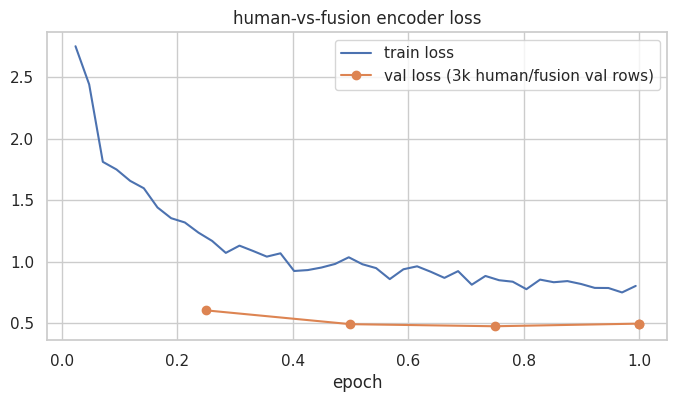

,epoch,eval_loss,eval_macro_f1
10,0.249941,0.605390,0.863953
22,0.499882,0.493276,0.890611
33,0.749822,0.476400,0.897200
45,0.999763,0.497656,0.891962
46,1.000000,0.497652,0.891962


In [6]:
log = pd.DataFrame(trainer.state.log_history)
ax = log.dropna(subset=['loss']).plot(x='epoch', y='loss', label='train loss', figsize=(8, 4))
log.dropna(subset=['eval_loss']).plot(x='epoch', y='eval_loss', marker='o', label='val loss (3k human/fusion val rows)', ax=ax)
plt.title('human-vs-fusion encoder loss'); plt.savefig(OUT / 'encoder_hf_loss.png', dpi=120, bbox_inches='tight'); plt.show()
log.dropna(subset=['eval_loss'])[['epoch', 'eval_loss', 'eval_macro_f1']]

**Observations.** Human-vs-fusion F1 peaks at 0.75 epoch (0.897) and dips slightly by the end (0.892). One epoch is enough.

## Predictions for all val/test texts and the human-vs-fusion comparison

In [7]:
def predict(seqs):
    order = np.argsort([len(s) for s in seqs])  # length-sorted batches = less padding
    out = trainer.predict(DS([seqs[i] for i in order])).predictions
    logits = np.empty_like(out); logits[order] = out
    return logits

t = time.time()
lv, lt = predict(seq_va), predict(seq_te)
print(f'inference {(time.time() - t) / 60:.0f} min')

hv = val.iloc[hf_val]
pred = lv[hf_val].argmax(1)
print(classification_report(hv.y2, pred, target_names=HF, digits=4))
rows = [{'model': 'specialist (03c), human vs fusion rows of val', 'binary_macro_f1': macro_f1(hv.y2, pred)}]
mon_tr = rng.choice(len(tr), min(3000, len(tr)), replace=False)
rows.append({'model': 'specialist on 3k TRAIN rows (overfit check)', 'binary_macro_f1': macro_f1(tr.y2.values[mon_tr], predict([seq_tr[i] for i in mon_tr]).argmax(1))})
try:  # same rows, the 3-class encoder from 03 deciding only between human and fusion
    e = hv[['id']].merge(pd.read_csv(find('encoder_val_logits.csv')), on='id')
    rows.append({'model': '3-class encoder (03), same rows, human vs fusion', 'binary_macro_f1': macro_f1(hv.y2, (e.enc_fusion > e.enc_human).astype(int))})
except FileNotFoundError:
    print('03 output not attached: skipping the comparison')
res = pd.DataFrame(rows).round(4)
res.to_csv(OUT / 'encoder_hf_results.csv', index=False)
res

inference 21 min
              precision    recall  f1-score   support

       human     0.9092    0.8700    0.8892      6723
      fusion     0.9004    0.9312    0.9156      8489

    accuracy                         0.9042     15212
   macro avg     0.9048    0.9006    0.9024     15212
weighted avg     0.9043    0.9042    0.9039     15212



,model,binary_macro_f1
0,"specialist (03c), human vs fusion rows of val",0.9024
1,specialist on 3k TRAIN rows (overfit check),0.9124
2,"3-class encoder (03), same rows, human vs fusion",0.8555


**Observations.** The specialist reaches binary macro-F1 **0.902** on the human/fusion val rows, against 0.856 for the 40k 3-class encoder (03) on the same rows, with a small train–val gap (0.912 vs 0.902). The fairer comparison is with 03b, whose per-class F1 on these classes (human 0.884, fusion 0.911) is close to the specialist's (0.889 / 0.916). A specialist trained on 135k human/fusion rows is roughly as good as the 3-class model trained on 245k rows. Its value is as an extra, partly independent stacking input: adding its logits raises the stack from 0.9673 (04, E2a) to 0.9702 (04b, E2a).

In [8]:
cols = ['hf_human', 'hf_fusion']
for df, lg, name in [(val, lv, 'val'), (test, lt, 'test')]:
    pd.DataFrame(lg, columns=cols).assign(hf_margin=lg[:, 1] - lg[:, 0], id=df.id.values).to_csv(OUT / f'encoder_hf_{name}_logits.csv', index=False)